# Gradient Boosting Lab — see every claim from the README with your own eyes

This notebook is the hands-on companion to [`../README.md`](../README.md).
Every lab is **self-contained**: a short goal, the code, the picture/numbers, and a
**"How to read this"** box that tells you what you should notice.

**How to use it**

1. Run the first code cell (imports). After that you can run any lab in order (`Shift + Enter` cell by cell),
   or `Kernel → Restart & Run All`. Labs only reuse data from *earlier* cells, so running top-to-bottom always works.
2. Read the "How to read this" box *after* looking at the output — try to guess first.
3. Change the numbers marked `# <- try changing this` and re-run to build intuition.

| Part | Labs | What it proves |
|---|---|---|
| **A. How gradient boosting works** | 1 – 6 | The hand-worked examples, residual = negative gradient, round-by-round fitting for regression, binary and multi-class |
| **B. Why it is useful in ML** | 7 – 11 | Beats a linear model and a random forest on non-linear tabular data; how learning rate, number of trees, early stopping and subsampling interact |
| **C. Where it fails (and why)** | 12 – 18 | The future (trend), unseen regions, interactions with stumps, outliers, noisy labels, linear targets, cost and tuning |

All datasets are generated in the notebook (or bundled with scikit-learn) — **no internet needed**.
The two datasets used across the labs are saved to `data/good_fit.csv` and `data/bad_fit.csv`; the from-scratch notebook
loads the same files.

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_circles, make_classification, make_friedman1, make_regression
from sklearn.ensemble import (GradientBoostingClassifier, GradientBoostingRegressor,
                              HistGradientBoostingRegressor, RandomForestRegressor)
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, log_loss, mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})


def rmse(y_true, y_pred):
    """Root mean squared error: a typical size of a mistake, in the units of y."""
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


def sigmoid(F):
    """Turn log-odds F into a probability (only used on moderate values in this notebook)."""
    return 1.0 / (1.0 + np.exp(-F))

---
# The two datasets

* **Good fit — `make_good_fit`**: Friedman's benchmark #1 (`make_friedman1`). Ten uniform features in [0, 1], only the
  first five matter, and the target mixes an **interaction** (`10·sin(π·x1·x2)`), a **curve** (`20·(x3−0.5)²`) and two
  straight lines (`10·x4 + 5·x5`), plus noise. This is the kind of tabular problem gradient boosting is built for.
* **Bad fit — `make_bad_fit`**: 40 years of monthly values with a steady **upward trend** and a yearly **season**.
  The task is to predict the **future** (the last 30 % of the months). Trees can only output values they saw in
  training, so gradient boosting flat-lines while a straight line keeps climbing (Lab 12).

good_fit: (2000, 10)  bad_fit: (480, 2)
  data/good_fit.csv: 196 kB
  data/bad_fit.csv: 7 kB


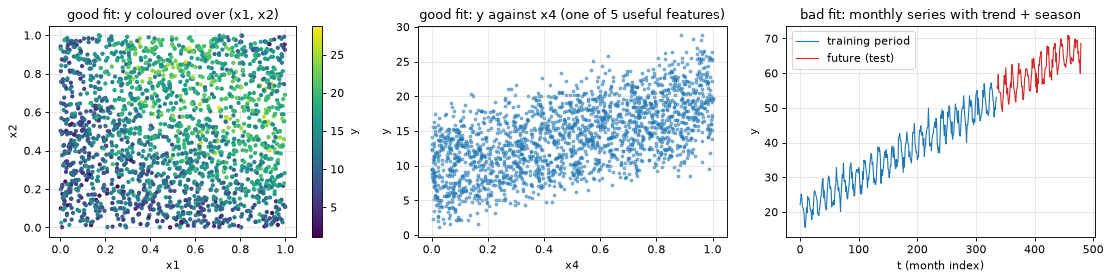

In [2]:
DATA = Path("data")
DATA.mkdir(exist_ok=True)


def make_good_fit(seed=0):
    """Friedman #1: y = 10 sin(pi x1 x2) + 20 (x3 - 0.5)^2 + 10 x4 + 5 x5 + noise; x6..x10 are pure noise."""
    X, y = make_friedman1(n_samples=2000, n_features=10, noise=1.0, random_state=seed)
    header = ",".join([f"x{j + 1}" for j in range(10)] + ["y"])
    np.savetxt(DATA / "good_fit.csv", np.column_stack([X, y]), delimiter=",", header=header, comments="", fmt="%.6g")
    return X, y


def make_bad_fit(seed=0):
    """Monthly series: y = 20 + 0.1 t + 4 sin(2 pi month / 12) + noise. Columns: t (0..479), month (1..12), y."""
    rng = np.random.default_rng(seed)
    t = np.arange(480)
    month = t % 12 + 1
    y = 20 + 0.1 * t + 4 * np.sin(2 * np.pi * month / 12) + rng.normal(0, 1.5, len(t))
    X = np.column_stack([t, month]).astype(float)
    np.savetxt(DATA / "bad_fit.csv", np.column_stack([X, y]), delimiter=",", header="t,month,y", comments="", fmt="%.6g")
    return X, y


X_good, y_good = make_good_fit(seed=0)
X_bad, y_bad = make_bad_fit(seed=0)
print("good_fit:", X_good.shape, " bad_fit:", X_bad.shape)
for name in ["good_fit.csv", "bad_fit.csv"]:
    print(f"  data/{name}: {(DATA / name).stat().st_size / 1e3:.0f} kB")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
sc = axes[0].scatter(X_good[:, 0], X_good[:, 1], c=y_good, s=8, cmap="viridis")
axes[0].set(title="good fit: y coloured over (x1, x2)", xlabel="x1", ylabel="x2")
plt.colorbar(sc, ax=axes[0], label="y")
axes[1].scatter(X_good[:, 3], y_good, s=6, alpha=0.5)
axes[1].set(title="good fit: y against x4 (one of 5 useful features)", xlabel="x4", ylabel="y")
cut = int(0.7 * len(y_bad))
axes[2].plot(X_bad[:cut, 0], y_bad[:cut], lw=1, label="training period")
axes[2].plot(X_bad[cut:, 0], y_bad[cut:], lw=1, color="tab:red", label="future (test)")
axes[2].set(title="bad fit: monthly series with trend + season", xlabel="t (month index)", ylabel="y")
axes[2].legend(loc="upper left")
plt.tight_layout(); plt.show()

> **How to read this**
> * Left: the colour pattern over (x1, x2) is a curved ridge — the **interaction** `sin(π·x1·x2)`. No single feature
>   explains it; you need both at once. Middle: x4 has a clear straight-line effect hidden under the other terms.
> * Right: the bad-fit series rises steadily and wiggles every 12 months. The red part is the **future** we will ask
>   the models to predict; its values are all **higher** than anything seen in training.

---
# Part A — How gradient boosting works

## Lab 1 · The hand-worked regression example, done by the computer

**Goal:** reproduce README section 5.1 number by number: six points, a constant start F₀ = mean, then three rounds
of "fit a stump (a one-split tree) to the residuals, add half of it" (learning rate η = 0.5).

F0 = mean(y) = 5.0
round | residuals y - F (what the tree must learn) | split   | leaf values (gamma) | new F
    1 | [-4. -3. -2.  1.  3.  5.]                  | x <= 3.5 | -3.000 / +3.000     | [3.5 3.5 3.5 6.5 6.5 6.5]
      | training MSE after this round: 3.9167
    2 | [-2.5 -1.5 -0.5 -0.5  1.5  3.5]            | x <= 4.5 | -1.250 / +2.500     | [2.875 2.875 2.875 5.875 7.75  7.75 ]
      | training MSE after this round: 1.5729
    3 | [-1.875 -0.875  0.125  0.125  0.25   2.25 ] | x <= 5.5 | -0.450 / +2.250     | [2.65  2.65  2.65  5.65  7.525 8.875]
      | training MSE after this round: 0.8135

scikit-learn, same settings, after each round:
 [[3.5   3.5   3.5   6.5   6.5   6.5  ]
 [2.875 2.875 2.875 5.875 7.75  7.75 ]
 [2.65  2.65  2.65  5.65  7.525 8.875]]
identical to the hand loop: True
prediction far outside the data, x = 7 and x = 100: [8.875 8.875]


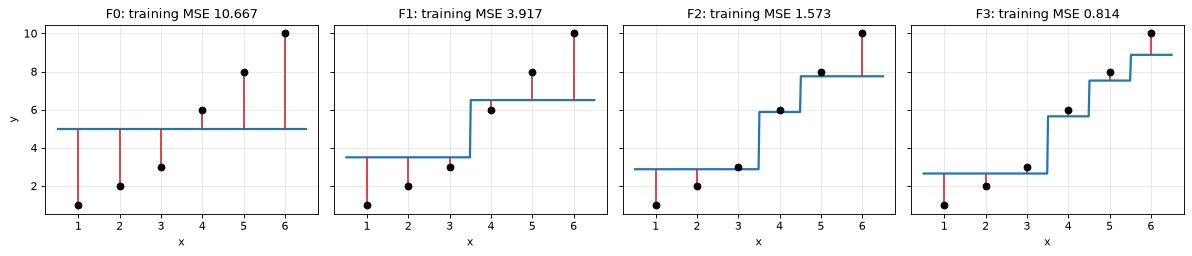

In [3]:
x_toy = np.arange(1, 7, dtype=float).reshape(-1, 1)        # 6 samples, 1 feature
y_toy = np.array([1, 2, 3, 6, 8, 10], dtype=float)
eta = 0.5                                                   # learning rate

F = np.full(6, y_toy.mean())                                # round 0: the best constant (the mean)
print(f"F0 = mean(y) = {y_toy.mean()}")
print(f"{'round':>5} | residuals y - F (what the tree must learn) | split   | leaf values (gamma) | new F")
history = [F.copy()]
for m in range(1, 4):
    r = y_toy - F                                           # pseudo-residuals (= negative gradient of 1/2 (y-F)^2)
    stump = DecisionTreeRegressor(max_depth=1).fit(x_toy, r)
    gamma = stump.predict(x_toy)                            # each leaf predicts the MEAN residual of its rows
    F = F + eta * gamma                                     # shrink the step, then add it
    history.append(F.copy())
    thr = stump.tree_.threshold[0]
    print(f"{m:>5} | {np.array2string(r, precision=3):<42} | x <= {thr:.1f} | "
          f"{gamma.min():+.3f} / {gamma.max():+.3f}     | {np.array2string(F, precision=3)}")
    print(f"      | training MSE after this round: {np.mean((y_toy - F) ** 2):.4f}")

sk = GradientBoostingRegressor(n_estimators=3, learning_rate=eta, max_depth=1).fit(x_toy, y_toy)
staged = np.array(list(sk.staged_predict(x_toy)))
print("\nscikit-learn, same settings, after each round:\n", staged)
print("identical to the hand loop:", np.allclose(staged, np.array(history[1:])))
print("prediction far outside the data, x = 7 and x = 100:", sk.predict([[7.0], [100.0]]))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.3), sharey=True)
grid = np.linspace(0.5, 6.5, 300).reshape(-1, 1)
curves = [np.full(len(grid), y_toy.mean())] + list(sk.staged_predict(grid))
for m, ax in enumerate(axes):
    ax.scatter(x_toy, y_toy, color="black", zorder=3)
    ax.plot(grid, curves[m], color="tab:blue", lw=2)
    ax.vlines(x_toy.ravel(), history[m], y_toy, color="tab:red", lw=1.5)
    ax.set(title=f"F{m}: training MSE {np.mean((y_toy - history[m]) ** 2):.3f}", xlabel="x")
axes[0].set_ylabel("y")
plt.tight_layout(); plt.show()

> **How to read this**
> * Round 0 predicts the mean, **5**, everywhere. Residuals are −4, −3, −2, 1, 3, 5 (the red lines in the first panel).
> * Round 1: the stump splits at **x ≤ 3.5**; its leaves hold the mean residual of each side, **−3** and **+3**. Only half
>   of that is added (η = 0.5), so F₁ = 3.5 / 6.5. Round 2 splits at **x ≤ 4.5** (−1.25 / +2.5) and round 3 at
>   **x ≤ 5.5** (−0.45 / +2.25) — each new tree goes after what is *still* wrong.
> * Training MSE falls **10.667 → 3.917 → 1.573 → 0.814**, exactly the README's numbers, and scikit-learn's
>   `staged_predict` gives the same F₁, F₂, F₃.
> * Far to the right (x = 7 or x = 100) the model answers **8.875** both times: a sum of step functions is flat outside
>   the data. Keep that in mind for Lab 12.

## Lab 2 · The binary-classification screenshots, recomputed

**Goal:** re-check the two lecture screenshots in README section 5.2 (placement data: `cgpa`, `iq` → `is_placed`,
learning rate 1, trees with 3 leaves). We let scikit-learn grow the trees and print every column of the screenshot's
table: log-odds, probability, residual and leaf for each round.

In [4]:
X_place = np.array([[6.82, 118], [6.36, 125], [5.39, 99], [5.50, 106],
                    [6.39, 148], [9.13, 148], [7.17, 147], [7.72, 72]])
y_place = np.array([0, 1, 1, 1, 0, 1, 1, 0])

clf = GradientBoostingClassifier(n_estimators=2, learning_rate=1.0, max_leaf_nodes=3,
                                 random_state=1).fit(X_place, y_place)     # random_state: see the tie note below
F0 = np.log(y_place.mean() / (1 - y_place.mean()))
print(f"p = 5/8 = {y_place.mean()},  F0 = ln(5/3) = {F0:.6f},  scikit-learn's F0 = {clf.init_.class_prior_[1]:.3f} -> "
      f"{np.log(clf.init_.class_prior_[1] / clf.init_.class_prior_[0]):.6f}")

F_rounds = [np.full(8, F0)] + [s.ravel() for s in clf.staged_decision_function(X_place)]
print(f"\n{'cgpa':>5} {'iq':>4} {'y':>2} | {'F0':>6} {'p0':>6} {'r1':>7} leaf1 | {'F1':>7} {'p1':>6} {'r2':>7} leaf2 | {'F2':>7} {'p2':>6}")
leaf1 = clf.estimators_[0, 0].apply(X_place.astype(np.float32))
leaf2 = clf.estimators_[1, 0].apply(X_place.astype(np.float32))
for i in range(8):
    p0, p1, p2 = (sigmoid(F_rounds[k][i]) for k in range(3))
    print(f"{X_place[i, 0]:>5} {X_place[i, 1]:>4.0f} {y_place[i]:>2} | {F_rounds[0][i]:6.3f} {p0:6.3f} {y_place[i] - p0:+7.3f} {leaf1[i]:>5} |"
          f" {F_rounds[1][i]:7.3f} {p1:6.3f} {y_place[i] - p1:+7.3f} {leaf2[i]:>5} | {F_rounds[2][i]:7.3f} {p2:6.3f}")

for m in range(2):
    t = clf.estimators_[m, 0].tree_
    leaves = np.nonzero(t.children_left == -1)[0]
    print(f"\ntree {m + 1}: splits", [(["cgpa", "iq"][f], round(th, 3)) for f, th in zip(t.feature, t.threshold) if f >= 0])
    for leaf in leaves:
        rows = (leaf1 if m == 0 else leaf2) == leaf
        r, p = y_place[rows] - sigmoid(F_rounds[m][rows]), sigmoid(F_rounds[m][rows])
        print(f"  leaf {leaf}: rows {np.nonzero(rows)[0] + 1}, sum r = {r.sum():+.4f}, sum p(1-p) = {(p * (1 - p)).sum():.4f}"
              f" -> gamma = {r.sum() / (p * (1 - p)).sum():+.4f}   (stored by scikit-learn: {t.value[leaf, 0, 0]:+.4f})")

query = np.array([[7.2, 100.0]])
F_query = clf.decision_function(query)[0]
print(f"\nquery (cgpa 7.2, iq 100): F = {F_query:.4f} -> p(placed) = {sigmoid(F_query):.4f} -> class {clf.predict(query)[0]}")
print("screenshot's sum: 0.51 + (-2.66) + 1.56 =", round(0.51 - 2.66 + 1.56, 2), "-> p =", round(sigmoid(-0.59), 2))

other = GradientBoostingClassifier(n_estimators=1, learning_rate=1.0, max_leaf_nodes=3, random_state=0).fit(X_place, y_place)
t0 = other.estimators_[0, 0].tree_
print("\ntie: with random_state=0 tree 1's second split is", [(["cgpa", "iq"][f], round(th, 3)) for f, th in zip(t0.feature, t0.threshold) if f >= 0],
      "- training log-loss after round 1:", round(log_loss(y_place, other.predict_proba(X_place)), 6), "vs",
      round(log_loss(y_place, sigmoid(np.c_[F_rounds[1]]).ravel()), 6))

p = 5/8 = 0.625,  F0 = ln(5/3) = 0.510826,  scikit-learn's F0 = 0.625 -> 0.510826

 cgpa   iq  y |     F0     p0      r1 leaf1 |      F1     p1      r2 leaf2 |      F2     p2
 6.82  118  0 |  0.511  0.625  -0.625     3 |  -2.156  0.104  -0.104     3 |  -1.579  0.171
 6.36  125  1 |  0.511  0.625  +0.375     1 |   2.111  0.892  +0.108     3 |   2.687  0.936
 5.39   99  1 |  0.511  0.625  +0.375     1 |   2.111  0.892  +0.108     3 |   2.687  0.936
  5.5  106  1 |  0.511  0.625  +0.375     1 |   2.111  0.892  +0.108     3 |   2.687  0.936
 6.39  148  0 |  0.511  0.625  -0.625     4 |   0.689  0.666  -0.666     4 |  -2.302  0.091
 9.13  148  1 |  0.511  0.625  +0.375     4 |   0.689  0.666  +0.334     2 |   1.738  0.850
 7.17  147  1 |  0.511  0.625  +0.375     4 |   0.689  0.666  +0.334     2 |   1.738  0.850
 7.72   72  0 |  0.511  0.625  -0.625     3 |  -2.156  0.104  -0.104     2 |  -1.106  0.249

tree 1: splits [('cgpa', np.float64(6.375)), ('iq', np.float64(132.5))]
  leaf 1: rows [

> **How to read this**
> * **Round 0** is right in the screenshot: p = 5/8 = 0.625, F₀ = ln(5/3) = **0.510826**, residuals **+0.375** (placed)
>   and **−0.625** (not placed).
> * **Tree 1** is right too: leaves {rows 2, 3, 4}, {1, 8}, {5, 6, 7} get γ = 1.125/0.703 = **1.6**,
>   −1.25/0.469 = **−2.6667** (the screenshot writes −2.66) and 0.125/0.703 = **0.1778** (the screenshot's table rounds it to
>   0.18 before adding, which is why its F₁ column reads 0.690826 instead of 0.6886).
> * **Tree 2** has the screenshot's structure (cgpa ≤ 6.995, then iq ≤ 136.5) and the same node means (0.015, −0.089,
>   0.188 …), but the Newton formula Σr / Σp(1−p) gives leaf values **+0.5767, −2.9909, +1.0497**, not the screenshot's
>   1.09, −2.94 (−2.49 in its table) and 1.56. We could not reproduce those three numbers from the formula (the lecture's
>   source was not recorded).
> * The query point lands in the −2.6667 leaf and then the +1.0497 leaf: F = 0.5108 − 2.6667 + 1.0497 = **−1.1061**, so
>   p = **0.249**. The screenshot's arithmetic (0.51 − 2.66 + 1.56 = −0.59 → 0.36) is right for its numbers; both give
>   class **0 (not placed)**.
> * **Ties:** in tree 1, "cgpa ≤ 6.995" and "iq ≤ 132.5" put exactly the same residual values on each side, so they are
>   equally good. Which one wins depends on the random order in which features are tried (`random_state`); the training
>   loss is identical either way.

## Lab 3 · A residual is a negative gradient

**Goal:** check README section 4.2's claim that the "residual" each tree learns is the **negative gradient** of the
loss with respect to the current prediction F: r = −∂L/∂F. We compare the formula with a numerical derivative
(nudge F a tiny bit, see how much L changes) for four losses.

y = 3.0, F = 1.0:
   squared  1/2 (y-F)^2       -dL/dF numeric = +2.000000   formula = +2.000000
   absolute |y-F|             -dL/dF numeric = +1.000000   formula = +1.000000
   Huber (delta=1)            -dL/dF numeric = +1.000000   formula = +1.000000
   log-loss  ln(1+e^F) - yF   -dL/dF numeric = +2.268941   formula = +2.268941
y = 3.0, F = 2.5:
   squared  1/2 (y-F)^2       -dL/dF numeric = +0.500000   formula = +0.500000
   absolute |y-F|             -dL/dF numeric = +1.000000   formula = +1.000000
   Huber (delta=1)            -dL/dF numeric = +0.500000   formula = +0.500000
   log-loss  ln(1+e^F) - yF   -dL/dF numeric = +2.075858   formula = +2.075858
y = 1.0, F = -0.4:
   squared  1/2 (y-F)^2       -dL/dF numeric = +1.400000   formula = +1.400000
   absolute |y-F|             -dL/dF numeric = +1.000000   formula = +1.000000
   Huber (delta=1)            -dL/dF numeric = +1.000000   formula = +1.000000
   log-loss  ln(1+e^F) - yF   -dL/dF numeric = +0.598688   formula = +0.5986

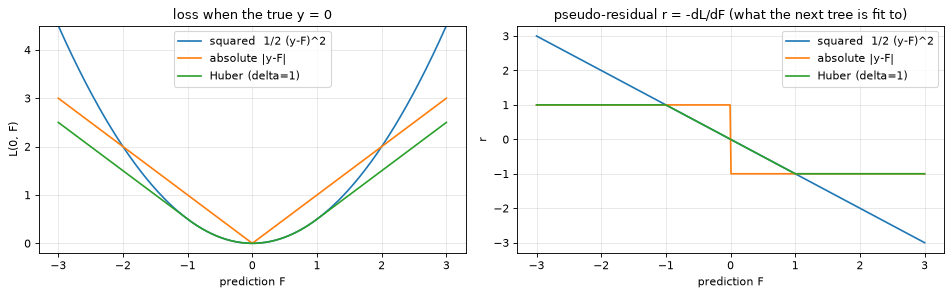

In [5]:
def losses(y, F, delta=1.0):
    """Per-sample loss L(y, F) for four loss functions (F = log-odds for the log-loss)."""
    a = np.abs(y - F)
    return {"squared  1/2 (y-F)^2": 0.5 * (y - F) ** 2,
            "absolute |y-F|": a,
            "Huber (delta=1)": np.where(a <= delta, 0.5 * a**2, delta * (a - 0.5 * delta)),
            "log-loss  ln(1+e^F) - yF": np.log1p(np.exp(F)) - y * F}


def residual_formulas(y, F, delta=1.0):
    """The pseudo-residuals r = -dL/dF written out by hand (README 4.2)."""
    return {"squared  1/2 (y-F)^2": y - F,
            "absolute |y-F|": np.sign(y - F),
            "Huber (delta=1)": np.clip(y - F, -delta, delta),
            "log-loss  ln(1+e^F) - yF": y - sigmoid(F)}


h = 1e-6
for y_val, F_val in [(3.0, 1.0), (3.0, 2.5), (1.0, -0.4)]:
    numeric = {k: -(losses(y_val, F_val + h)[k] - losses(y_val, F_val - h)[k]) / (2 * h) for k in losses(y_val, F_val)}
    formula = residual_formulas(y_val, F_val)
    print(f"y = {y_val}, F = {F_val}:")
    for k in numeric:
        print(f"   {k:<26} -dL/dF numeric = {numeric[k]:+.6f}   formula = {formula[k]:+.6f}")

print("\nWith the OTHER common convention L = (y-F)^2 (no 1/2): -dL/dF = 2 (y - F) =",
      -((3 - (1 + h)) ** 2 - (3 - (1 - h)) ** 2) / (2 * h), "at y=3, F=1  -> same direction, twice as long")

F_grid = np.linspace(-3, 3, 400)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for k, L in losses(0.0, F_grid).items():
    if k.startswith("log"):
        continue
    axes[0].plot(F_grid, L, label=k)
    axes[1].plot(F_grid, residual_formulas(0.0, F_grid)[k], label=k)
axes[0].set(title="loss when the true y = 0", xlabel="prediction F", ylabel="L(0, F)", ylim=(-0.2, 4.5))
axes[1].set(title="pseudo-residual r = -dL/dF (what the next tree is fit to)", xlabel="prediction F", ylabel="r")
axes[0].legend(); axes[1].legend(loc="upper right")
plt.tight_layout(); plt.show()

> **How to read this**
> * For every loss and every (y, F), the numerical slope and the hand formula agree to 6 decimals: **the residual
>   y − F is exactly the negative gradient of ½(y − F)²** — nothing exotic, the ordinary squared error. For log-loss in
>   log-odds the negative gradient is again "y minus prediction", y − p.
> * If you write the loss as (y − F)² (no ½) or average it over n samples, the gradient is 2(y − F) or (2/n)(y − F):
>   same direction, different length. It does not matter, because each leaf's value is chosen afterwards by its own
>   line search (README 4.3); the ½ just keeps the formulas clean.
> * Right panel: squared loss pushes harder the further off you are (straight line); absolute loss only says
>   "up" or "down" (±1); Huber is squared near the target and capped far away. That cap is why Huber and absolute
>   loss resist outliers (Lab 15).

## Lab 4 · Watching the fit grow, round by round

**Goal:** see "each tree fixes what the previous ones got wrong" on a 1-D curve, and the training error shrinking.

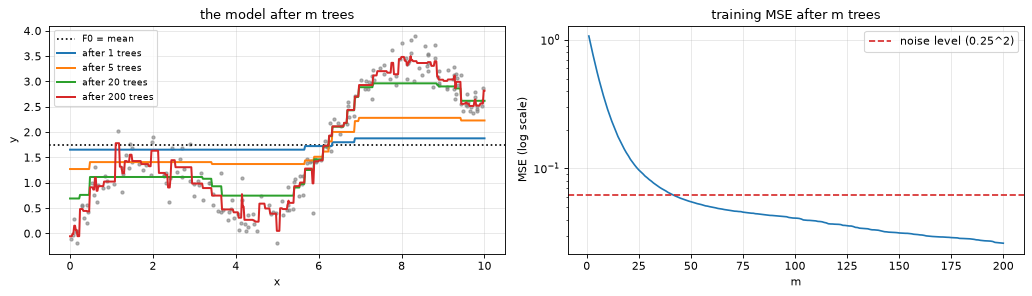

after   1 trees: training MSE = 1.0700
after   5 trees: training MSE = 0.5586
after  20 trees: training MSE = 0.1252
after  50 trees: training MSE = 0.0551
after 200 trees: training MSE = 0.0262


In [6]:
rng = np.random.default_rng(0)
x1d = np.sort(rng.uniform(0, 10, 200)).reshape(-1, 1)
y1d = np.sin(x1d.ravel()) + 0.3 * x1d.ravel() + rng.normal(0, 0.25, 200)

gb1d = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, max_depth=2, random_state=0).fit(x1d, y1d)  # <- try changing this
grid = np.linspace(0, 10, 500).reshape(-1, 1)
staged_grid = list(gb1d.staged_predict(grid))
train_mse = [mean_squared_error(y1d, p) for p in gb1d.staged_predict(x1d)]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].scatter(x1d, y1d, s=8, color="gray", alpha=0.6)
axes[0].axhline(y1d.mean(), color="black", ls=":", label="F0 = mean")
for m in [1, 5, 20, 200]:
    axes[0].plot(grid, staged_grid[m - 1], lw=1.8, label=f"after {m} trees")
axes[0].set(title="the model after m trees", xlabel="x", ylabel="y"); axes[0].legend(fontsize=8)
axes[1].plot(range(1, 201), train_mse)
axes[1].axhline(0.25**2, color="tab:red", ls="--", label="noise level (0.25^2)")
axes[1].set(yscale="log", title="training MSE after m trees", xlabel="m", ylabel="MSE (log scale)"); axes[1].legend()
plt.tight_layout(); plt.show()
for m in [1, 5, 20, 50, 200]:
    print(f"after {m:>3} trees: training MSE = {train_mse[m - 1]:.4f}")

> **How to read this**
> * After 1 tree the model is a crude staircase; after 5 it follows the trend; after 20 the waves appear; after 200 it
>   hugs the data.
> * Training MSE falls fast at first (1.07 → 0.56 → 0.13 after 1, 5, 20 trees) and then slowly. It crosses the noise
>   level (0.0625) after about 45 trees and keeps going down (0.026 after 200): from there on the trees are fitting the
>   noise — look at the little spikes in the red curve. That is why we watch a *validation* set (Lab 8), not the
>   training error.

## Lab 5 · Binary classification step by step (circles)

**Goal:** the round-by-round walkthrough from the old notes (a tutorial by T. Masui, see README Further reading),
with 2-D pictures. A slightly imbalanced circles dataset; stumps; η = 0.9 so each round is visible. We do the loop
**by hand** — F₀ = log-odds, residual y − p, a regression stump on the residuals, Newton leaf values Σr/Σp(1−p) — and
check it against `GradientBoostingClassifier`.

90 points, p = mean(y) = 0.556, F0 = ln(p/(1-p)) = 0.223
  round 1: leaf 1 (79 pts) mean residual +0.077 -> gamma +0.313
  round 1: leaf 2 (11 pts) mean residual -0.556 -> gamma -2.250
round 1: split x1 <= 0.640, training log-loss 0.5959
  round 2: leaf 1 (13 pts) mean residual -0.547 -> gamma -2.329
  round 2: leaf 2 (77 pts) mean residual +0.082 -> gamma +0.373
round 2: split x1 <= -0.630, training log-loss 0.4916
  round 3: leaf 1 ( 7 pts) mean residual -0.699 -> gamma -3.319
  round 3: leaf 2 (83 pts) mean residual +0.054 -> gamma +0.284
round 3: split x2 <= -0.826, training log-loss 0.3998
  round 4: leaf 1 (82 pts) mean residual +0.064 -> gamma +0.369
  round 4: leaf 2 ( 8 pts) mean residual -0.685 -> gamma -3.673
round 4: split x2 <= 0.820, training log-loss 0.2866
hand loop == scikit-learn: True
old notebook's check (20 stumps, eta 0.1): log-loss 0.461943067988696


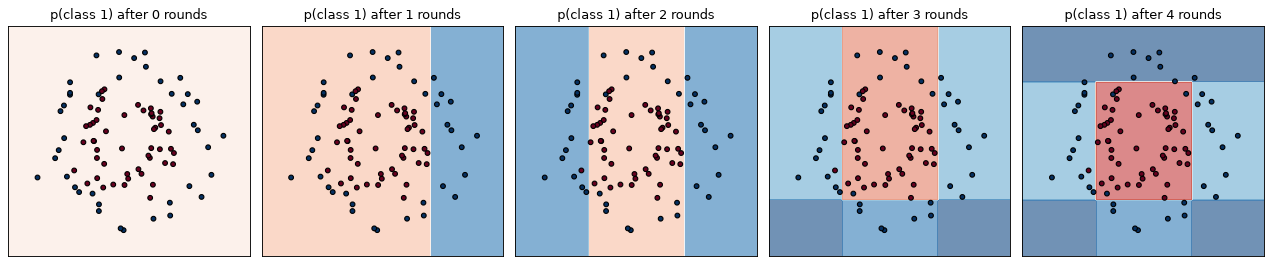

In [7]:
Xc, yc = make_circles(n_samples=100, factor=0.5, noise=0.15, random_state=0)
keep = np.sort(np.append(np.where(yc == 1)[0], np.where(yc == 0)[0][:-10]))    # drop 10 class-0 points
Xc, yc = Xc[keep], yc[keep]
eta_c, n_rounds = 0.9, 4                                                       # <- try changing this

p_bar = yc.mean()
F = np.full(len(yc), np.log(p_bar / (1 - p_bar)))                               # F0 = log-odds, NOT p
print(f"{len(yc)} points, p = mean(y) = {p_bar:.3f}, F0 = ln(p/(1-p)) = {F[0]:.3f}")
g1, g2 = np.meshgrid(np.linspace(-1.6, 1.6, 200), np.linspace(-1.6, 1.6, 200))
grid2 = np.c_[g1.ravel(), g2.ravel()]
F_grid = np.full(len(grid2), F[0])
snapshots = [sigmoid(F_grid).copy()]
for m in range(1, n_rounds + 1):
    p = sigmoid(F)
    r = yc - p                                                                  # residuals in probability units
    stump = DecisionTreeRegressor(max_depth=1, random_state=0).fit(Xc, r)
    leaf_of_row, leaf_of_grid = stump.apply(Xc), stump.apply(grid2)
    for leaf in np.unique(leaf_of_row):
        rows = leaf_of_row == leaf
        gamma = r[rows].sum() / (p[rows] * (1 - p[rows])).sum()                 # Newton step, in log-odds units
        F[rows] += eta_c * gamma
        F_grid[leaf_of_grid == leaf] += eta_c * gamma
        print(f"  round {m}: leaf {leaf} ({rows.sum():>2} pts) mean residual {r[rows].mean():+.3f} -> gamma {gamma:+.3f}")
    snapshots.append(sigmoid(F_grid).copy())
    print(f"round {m}: split x{stump.tree_.feature[0] + 1} <= {stump.tree_.threshold[0]:.3f}, "
          f"training log-loss {log_loss(yc, sigmoid(F)):.4f}")

sk_c = GradientBoostingClassifier(n_estimators=n_rounds, learning_rate=eta_c, max_depth=1, random_state=0).fit(Xc, yc)
print("hand loop == scikit-learn:", np.allclose(sigmoid(F), sk_c.predict_proba(Xc)[:, 1]))
old = GradientBoostingClassifier(n_estimators=20, learning_rate=0.1, max_depth=1).fit(Xc, yc)
print(f"old notebook's check (20 stumps, eta 0.1): log-loss {log_loss(yc, old.predict_proba(Xc)):.15f}")

fig, axes = plt.subplots(1, n_rounds + 1, figsize=(16, 3.4))
for m, ax in enumerate(axes):
    ax.contourf(g1, g2, snapshots[m].reshape(g1.shape), levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=0.6)
    ax.scatter(Xc[:, 0], Xc[:, 1], c=yc, cmap="RdBu_r", edgecolor="k", s=18)
    ax.set(title=f"p(class 1) after {m} rounds", xticks=[], yticks=[])
plt.tight_layout(); plt.show()

> **How to read this**
> * F₀ is the **log-odds** ln(0.556/0.444) = **0.223**, not the probability 0.556 itself; probabilities come back
>   through the sigmoid. Every panel's colour is p = sigmoid(F).
> * Each round adds one axis-parallel cut: the first stump splits on x1 and pushes the right-hand strip towards
>   class 0 (γ = −2.25 in log-odds; the tutorial printed −2.2), later stumps carve the other sides. After 4 stumps the inner disk is starting to be
>   boxed in; more rounds keep sharpening the box.
> * The hand loop and `GradientBoostingClassifier` give **identical** probabilities, and the old notebook's check
>   (20 stumps, η = 0.1) gives log-loss **0.461943067988696**, the number printed in the old notes — but now from
>   bug-free code (the from-scratch notebook shows the three bugs in the old class).

## Lab 6 · More than two classes: K trees per round

**Goal:** README section 4.6. For K classes the model keeps K scores (logits) per sample and turns them into
probabilities with the **softmax**. scikit-learn fits **K regression trees per round**, one per class, each on
y_k − p_k. Check: the starting scores sum to 0, adding a constant to all scores changes nothing, the leaf formula has a
(K−1)/K factor, and binary problems use 1 tree, not 2.

estimators_ shape (rounds, trees per round): (50, 3)
binary problem (circles) estimators_ shape  : (4, 1)
class priors n_k/n: [0.33  0.332 0.338]  -> F0 = [-0.01  -0.005  0.015]  sum = 0.0
softmax(F0) gives back the priors: [0.33  0.332 0.338]
probabilities from scores     :
 [[0.976 0.02  0.004]
 [0.005 0.017 0.978]
 [0.017 0.955 0.028]]
probabilities from scores +100:
 [[0.976 0.02  0.004]
 [0.005 0.017 0.978]
 [0.017 0.955 0.028]]
class 0: leaf 3 value by hand +1.883835   stored by scikit-learn +1.883835
class 1: leaf 3 value by hand +0.069691   stored by scikit-learn +0.069691
class 2: leaf 5 value by hand -0.975791   stored by scikit-learn -0.975791


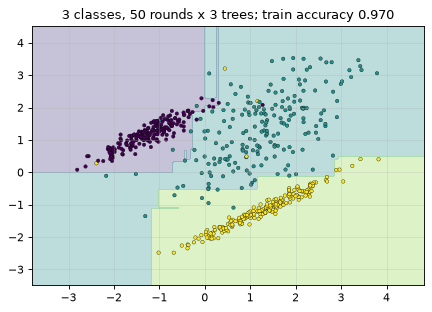

In [8]:
X3, y3 = make_classification(n_samples=600, n_features=2, n_informative=2, n_redundant=0, n_classes=3,
                             n_clusters_per_class=1, class_sep=1.2, random_state=0)
clf3 = GradientBoostingClassifier(n_estimators=50, learning_rate=0.1, max_depth=2, random_state=0).fit(X3, y3)
print("estimators_ shape (rounds, trees per round):", clf3.estimators_.shape)
print("binary problem (circles) estimators_ shape  :", sk_c.estimators_.shape)

prior = np.bincount(y3) / len(y3)
F0_3 = clf3._raw_predict_init(X3[:1].astype(np.float32))[0]
print("class priors n_k/n:", prior, " -> F0 =", F0_3, " sum =", round(F0_3.sum(), 12))
print("softmax(F0) gives back the priors:", np.exp(F0_3) / np.exp(F0_3).sum())

raw = clf3.decision_function(X3[:3])
shifted = raw + 100.0
softmax_rows = lambda Z: np.exp(Z - Z.max(axis=1, keepdims=True)) / np.exp(Z - Z.max(axis=1, keepdims=True)).sum(axis=1, keepdims=True)
print("probabilities from scores     :\n", softmax_rows(raw))
print("probabilities from scores +100:\n", softmax_rows(shifted))

# leaf formula of round 1, class k: (K-1)/K * sum(r) / sum(p(1-p)), with p = prior and r = y_k - p_k
K = 3
for k in range(K):
    tree = clf3.estimators_[0, k]
    leaves = tree.apply(X3.astype(np.float32))
    leaf = leaves[0]
    rows = leaves == leaf
    r = (y3[rows] == k) - prior[k]
    by_hand = (K - 1) / K * r.sum() / (rows.sum() * prior[k] * (1 - prior[k]))
    print(f"class {k}: leaf {leaf} value by hand {by_hand:+.6f}   stored by scikit-learn {tree.tree_.value[leaf, 0, 0]:+.6f}")

g1, g2 = np.meshgrid(np.linspace(X3[:, 0].min() - 1, X3[:, 0].max() + 1, 200), np.linspace(X3[:, 1].min() - 1, X3[:, 1].max() + 1, 200))
pred = clf3.predict(np.c_[g1.ravel(), g2.ravel()]).reshape(g1.shape)
plt.figure(figsize=(5.5, 4))
plt.contourf(g1, g2, pred, alpha=0.3, levels=[-0.5, 0.5, 1.5, 2.5], cmap="viridis")
plt.scatter(X3[:, 0], X3[:, 1], c=y3, s=10, cmap="viridis", edgecolor="k", linewidth=0.3)
plt.title(f"3 classes, 50 rounds x 3 trees; train accuracy {clf3.score(X3, y3):.3f}")
plt.tight_layout(); plt.show()

> **How to read this**
> * 50 rounds × **3 trees** for 3 classes, but 4 × **1** tree for the binary circles: a binary problem needs only one
>   score (the sigmoid is a softmax with the other class's score fixed at 0).
> * The starting scores are ln(p_k) minus their average, so they **sum to 0**, and softmax(F₀) returns the class
>   frequencies. Adding 100 to every score leaves the probabilities unchanged: only *differences* between scores
>   matter, so one of the K scores is redundant (over-parametrisation). scikit-learn removes the redundancy only at the
>   start (sum-to-zero F₀) and then fits all K trees anyway.
> * The leaf values match (K−1)/K · Σr / Σp(1−p) exactly. The (K−1)/K factor comes from Friedman's paper; scikit-learn
>   keeps it for backward compatibility and notes it simply rescales the learning rate.

---
# Part B — Why gradient boosting is useful

## Lab 7 · Good fit: non-linear tabular data

**Goal:** README section 7. On the good-fit data, compare a linear model, one tuned tree, a random forest and
gradient boosting. **No leakage:** we split train / validation / test = 60 / 20 / 20; every choice (tree depth, number
of boosting rounds) is made on the validation set; the test set is used **once** at the end.

In [9]:
X_tv, X_te, y_tv, y_te = train_test_split(X_good, y_good, test_size=0.2, random_state=0)
X_tr, X_va, y_tr, y_va = train_test_split(X_tv, y_tv, test_size=0.25, random_state=0)
print("train / validation / test sizes:", len(y_tr), len(y_va), len(y_te))

lin = LinearRegression().fit(X_tr, y_tr)
depths = range(1, 13)
tree_val = [mean_squared_error(y_va, DecisionTreeRegressor(max_depth=d, random_state=0).fit(X_tr, y_tr).predict(X_va)) for d in depths]
best_depth = depths[int(np.argmin(tree_val))]
tree = DecisionTreeRegressor(max_depth=best_depth, random_state=0).fit(X_tr, y_tr)
rf = RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=-1).fit(X_tr, y_tr)

gb_full = GradientBoostingRegressor(n_estimators=1000, learning_rate=0.1, max_depth=3, random_state=0).fit(X_tr, y_tr)
gb_val = [mean_squared_error(y_va, p) for p in gb_full.staged_predict(X_va)]
best_n = int(np.argmin(gb_val)) + 1
gb = GradientBoostingRegressor(n_estimators=best_n, learning_rate=0.1, max_depth=3, random_state=0).fit(X_tr, y_tr)
print(f"chosen on validation: tree depth = {best_depth}, boosting rounds = {best_n}")

print(f"\n{'model':<26}{'test MSE':>10}{'test R2':>9}")
for name, model in [("linear regression", lin), (f"decision tree (depth {best_depth})", tree),
                    ("random forest (300 trees)", rf), (f"gradient boosting ({best_n})", gb)]:
    pred = model.predict(X_te)
    print(f"{name:<26}{mean_squared_error(y_te, pred):>10.3f}{r2_score(y_te, pred):>9.3f}")
print("noise variance in the data: 1.0 (the best possible test MSE)")

train / validation / test sizes: 1200 400 400


chosen on validation: tree depth = 8, boosting rounds = 499

model                       test MSE  test R2
linear regression              7.353    0.693
decision tree (depth 8)        7.056    0.705
random forest (300 trees)      3.650    0.847
gradient boosting (499)        2.072    0.913
noise variance in the data: 1.0 (the best possible test MSE)


> **How to read this**
> * Gradient boosting has the lowest test error (MSE **2.07**, R² **0.913**), ahead of the random forest (**3.65**,
>   R² 0.847), one depth-8 tree (**7.06**) and the linear model (**7.35**). The noise floor is 1.0.
> * Why the linear model loses: it cannot bend (the x3 curve) or multiply features (the x1·x2 interaction).
> * Why boosting edges out the forest: the forest averages deep trees grown independently on the *same* target, so its
>   error is mostly the bias each tree shares; boosting keeps fitting what is still wrong, one small tree at a time,
>   so it removes bias step by step (README section 7).

## Lab 8 · Train and validation curves with `staged_predict`

**Goal:** README section 6.4. `staged_predict` replays the model after 1, 2, …, M trees, so one fit gives the whole
learning curve. Training error keeps falling; validation error falls, flattens and then slowly rises — that turning
point is where to stop.

depth 3: best validation MSE 1.837 at 499 trees; at 1000 trees: validation 1.848, training 0.051925


depth 6: best validation MSE 2.218 at 515 trees; at 1000 trees: validation 2.218, training 0.000001


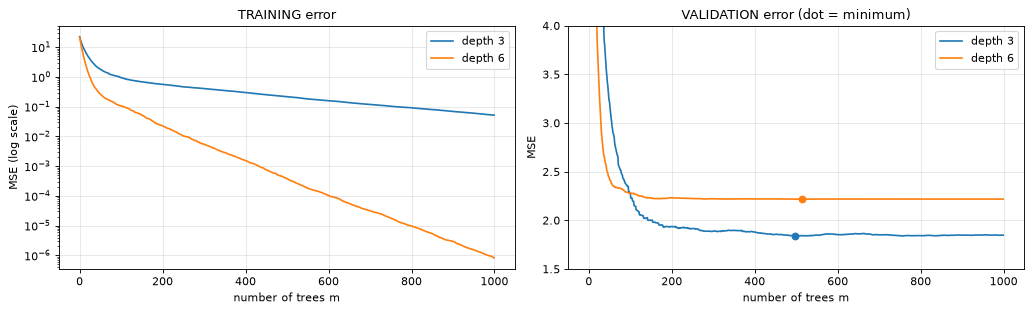

In [10]:
gb_deep = GradientBoostingRegressor(n_estimators=1000, learning_rate=0.1, max_depth=6, random_state=0).fit(X_tr, y_tr)
curves = {"depth 3": gb_full, "depth 6": gb_deep}
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for (name, model), color in zip(curves.items(), ["tab:blue", "tab:orange"]):
    tr_curve = [mean_squared_error(y_tr, p) for p in model.staged_predict(X_tr)]
    va_curve = [mean_squared_error(y_va, p) for p in model.staged_predict(X_va)]
    axes[0].plot(tr_curve, color=color, label=name)
    axes[1].plot(va_curve, color=color, label=name)
    best = int(np.argmin(va_curve))
    axes[1].scatter(best, va_curve[best], color=color, zorder=3)
    print(f"{name}: best validation MSE {va_curve[best]:.3f} at {best + 1} trees; "
          f"at 1000 trees: validation {va_curve[-1]:.3f}, training {tr_curve[-1]:.6f}")
axes[0].set(yscale="log", xlabel="number of trees m", ylabel="MSE (log scale)", title="TRAINING error")
axes[1].set(ylim=(1.5, 4), xlabel="number of trees m", ylabel="MSE", title="VALIDATION error (dot = minimum)")
axes[0].legend(); axes[1].legend(); plt.tight_layout(); plt.show()

> **How to read this**
> * Training error (left) only goes down — with depth-6 trees it reaches about 0.000001, far below the noise level
>   of 1: pure memorisation.
> * Validation error (right) is what matters. Depth 3 bottoms out at **1.837 after 499 trees** and then creeps up
>   (1.848 at 1000). Depth 6 is worse everywhere (best **2.218**) and then simply freezes: once the training data is
>   memorised the residuals are ~0 and new trees add nothing — the noise it learned stays in the model.
> * The number of trees is therefore a **tuning knob read off a validation curve**, never off the training error and
>   never off the test set.

## Lab 9 · Learning rate × number of trees (the old "test this!")

**Goal:** the old notes asked: *"low learning rate → more models? Test this!"* We fit with five learning rates and
read, on the validation set, how many trees each needs and how good it gets.

eta = 1.0   best number of trees =    16   best validation MSE = 4.953


eta = 0.5   best number of trees =    54   best validation MSE = 2.353


eta = 0.2   best number of trees =   188   best validation MSE = 1.887


eta = 0.1   best number of trees =   499   best validation MSE = 1.837


eta = 0.05  best number of trees =   617   best validation MSE = 1.829


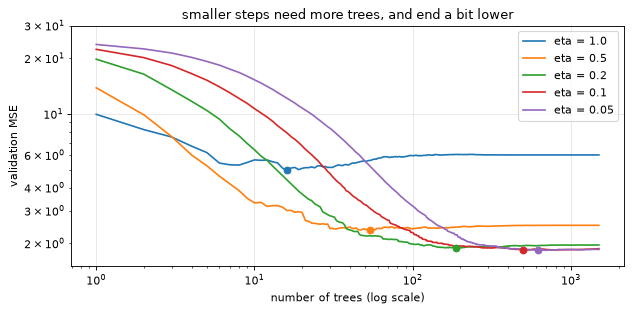

In [11]:
results = []
for lr in [1.0, 0.5, 0.2, 0.1, 0.05]:                                   # <- try changing this
    t0 = time.perf_counter()
    model = GradientBoostingRegressor(n_estimators=1500, learning_rate=lr, max_depth=3, random_state=0).fit(X_tr, y_tr)
    va = [mean_squared_error(y_va, p) for p in model.staged_predict(X_va)]
    results.append((lr, int(np.argmin(va)) + 1, min(va), va, time.perf_counter() - t0))
    print(f"eta = {lr:<5} best number of trees = {results[-1][1]:>5}   best validation MSE = {results[-1][2]:.3f}")

fig, ax = plt.subplots(figsize=(8, 4))
for lr, n_best, v_best, va, _ in results:
    ax.plot(range(1, len(va) + 1), va, label=f"eta = {lr}")
    ax.scatter(n_best, v_best, zorder=3)
ax.set(xscale="log", yscale="log", ylim=(1.5, 30), xlabel="number of trees (log scale)", ylabel="validation MSE",
       title="smaller steps need more trees, and end a bit lower")
ax.legend(); plt.tight_layout(); plt.show()

> **How to read this**
> * Tested: halving the learning rate roughly multiplies the number of trees needed (η = 1 → **16** trees, 0.5 → **54**,
>   0.2 → **188**, 0.1 → **499**, 0.05 → **617**). The trend is clear even if it is not an exact ×2 every time.
> * The best validation error also improves as η shrinks (**4.95 → 2.35 → 1.89 → 1.84 → 1.83**), with diminishing
>   returns below 0.1. Big steps overshoot: η = 1 starts over-fitting after a handful of trees.
> * Practical rule: pick a small η (0.05–0.1), then let the validation curve or early stopping (next lab) choose the
>   number of trees. The price is fit time, which grows with the number of trees.

## Lab 10 · Early stopping: `n_iter_no_change` (and what `validation_fraction` really does)

**Goal:** README section 6.2. With `n_iter_no_change=k`, scikit-learn holds out `validation_fraction` of the
**training** data and stops when the validation loss has not improved by more than `tol` for k rounds in a row.
Without `n_iter_no_change`, `validation_fraction` is **ignored**.

In [12]:
es = GradientBoostingRegressor(n_estimators=5000, learning_rate=0.1, n_iter_no_change=10, validation_fraction=0.1,
                               tol=1e-4, random_state=0).fit(X_tv, y_tv)            # <- try n_iter_no_change
print(f"asked for up to 5000 trees, early stopping kept n_estimators_ = {es.n_estimators_}")

plain = GradientBoostingRegressor(n_estimators=100, random_state=0).fit(X_tv, y_tv)
with_vf = GradientBoostingRegressor(n_estimators=100, validation_fraction=0.5, random_state=0).fit(X_tv, y_tv)
print("validation_fraction=0.5 WITHOUT n_iter_no_change: n_estimators_ =", with_vf.n_estimators_,
      "| predictions identical to the default model:", np.array_equal(plain.predict(X_te), with_vf.predict(X_te)))
print(f"test MSE of the early-stopped model (test set used once): {mean_squared_error(y_te, es.predict(X_te)):.3f}")

asked for up to 5000 trees, early stopping kept n_estimators_ = 152


validation_fraction=0.5 WITHOUT n_iter_no_change: n_estimators_ = 100 | predictions identical to the default model: True
test MSE of the early-stopped model (test set used once): 2.080


> **How to read this**
> * Early stopping chose **152 rounds** on its own, from an internal 10 % slice of the training data (the test set
>   was never consulted), and the test MSE (**2.08**) matches Lab 7's hand-tuned model (2.07).
> * The old notes said "`validation_fraction` is 0.1 by default, so we already have a validation set within the
>   model" — only true when `n_iter_no_change` is set. Without it, `validation_fraction=0.5` changes **nothing**:
>   100 trees, identical predictions.
> * The old notebook also reported a "validation score" computed on the test set; using the test set to choose
>   settings makes the final test score optimistic. Here selection happens on validation data only.

## Lab 11 · Stochastic gradient boosting: `subsample` (answering the old red question)

**Goal:** the old notes asked whether `subsample` draws one subset once, or a new subset for every tree. We record the
sample mask scikit-learn uses at each round (via the `monitor` callback) and then compare validation curves.

round 1: 600 of 1200 rows in-bag (a True/False mask: each row at most once)
round 2: 600 of 1200 rows in-bag (a True/False mask: each row at most once), 309 shared with round 1
round 3: 600 of 1200 rows in-bag (a True/False mask: each row at most once), 303 shared with round 2
round 4: 600 of 1200 rows in-bag (a True/False mask: each row at most once), 294 shared with round 3
round 5: 600 of 1200 rows in-bag (a True/False mask: each row at most once), 295 shared with round 4


subsample = 1.0: best validation MSE 1.837 at 499 trees, at 1000 trees 1.848


subsample = 0.5: best validation MSE 1.577 at 297 trees, at 1000 trees 1.646


subsample = 0.3: best validation MSE 1.583 at 415 trees, at 1000 trees 1.701


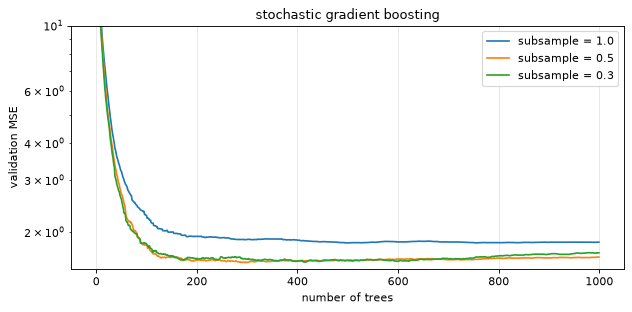

In [13]:
masks = []


def record_mask(i, est, local_vars):
    """Called by scikit-learn after each round; keep a copy of that round's in-bag mask."""
    masks.append(local_vars["sample_mask"].copy())
    return False                                                    # False = do not stop


GradientBoostingRegressor(n_estimators=5, subsample=0.5, random_state=0).fit(X_tr, y_tr, monitor=record_mask)
for i, mask in enumerate(masks):
    overlap = (mask & masks[i - 1]).sum() if i else 0
    print(f"round {i + 1}: {mask.sum()} of {len(mask)} rows in-bag (a True/False mask: each row at most once)"
          + (f", {overlap} shared with round {i}" if i else ""))

fig, ax = plt.subplots(figsize=(8, 4))
for sub in [1.0, 0.5, 0.3]:                                            # <- try changing this
    model = GradientBoostingRegressor(n_estimators=1000, learning_rate=0.1, subsample=sub, random_state=0).fit(X_tr, y_tr)
    va = [mean_squared_error(y_va, p) for p in model.staged_predict(X_va)]
    ax.plot(va, label=f"subsample = {sub}")
    print(f"subsample = {sub}: best validation MSE {min(va):.3f} at {int(np.argmin(va)) + 1} trees, at 1000 trees {va[-1]:.3f}")
ax.set(yscale="log", ylim=(1.5, 10), xlabel="number of trees", ylabel="validation MSE", title="stochastic gradient boosting")
ax.legend(); plt.tight_layout(); plt.show()

> **How to read this**
> * **A new subset at every round, drawn without replacement**: each round uses exactly 600 of 1200 rows (a boolean
>   mask, so no row twice), and consecutive rounds share only about half of them — a fresh random draw each time.
> * Subsampling adds randomness that decorrelates the trees (like bagging) and halves the work per tree. Here it
>   also **helps**: best validation MSE **1.577** with `subsample=0.5` (and 1.583 with 0.3) versus **1.837** with all
>   rows. Friedman (2002) found 0.5–0.8 a good default range.
> * Bonus: with `subsample < 1` the fitted model also has `oob_improvement_` (loss change on the left-out rows), a cheap
>   but noisy way to watch progress.

---
# Part C — Where gradient boosting fails

## Lab 12 · Bad fit: predicting the future of a trending series

**Goal:** README section 8.1. Train on the first 70 % of the months, predict the last 30 %. Trees split on `t`, and
every leaf stores a value seen in training, so the forecast can never rise above the training data. A linear model
with a trend term and season terms (sin/cos of the month) keeps climbing. We also try the usual fix: model the trend
linearly and let boosting learn what is left.

model                                  train RMSE  future RMSE
gradient boosting                            0.64         9.52
random forest                                0.69         9.02
linear: trend + season                       1.50         1.63
linear trend + boosting on the rest          0.63         1.76
highest y in training: 57.2; highest boosting forecast: 55.6; highest true future y: 70.9


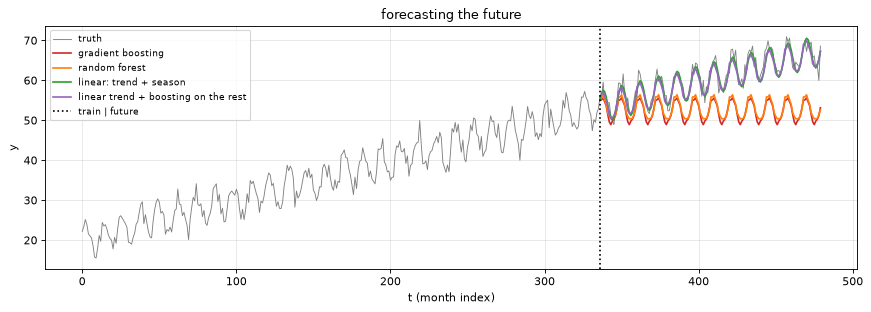

In [14]:
cut = int(0.7 * len(y_bad))
Xb_tr, Xb_te, yb_tr, yb_te = X_bad[:cut], X_bad[cut:], y_bad[:cut], y_bad[cut:]


def trend_season_features(X):
    """[t, sin(2 pi month/12), cos(2 pi month/12)] - what a linear model needs to describe trend + season."""
    angle = 2 * np.pi * X[:, 1] / 12
    return np.column_stack([X[:, 0], np.sin(angle), np.cos(angle)])


gb_b = GradientBoostingRegressor(n_estimators=300, learning_rate=0.1, random_state=0).fit(Xb_tr, yb_tr)
rf_b = RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=-1).fit(Xb_tr, yb_tr)
lin_b = LinearRegression().fit(trend_season_features(Xb_tr), yb_tr)
trend = LinearRegression().fit(Xb_tr[:, :1], yb_tr)
gb_resid = GradientBoostingRegressor(n_estimators=300, learning_rate=0.1, random_state=0).fit(
    Xb_tr, yb_tr - trend.predict(Xb_tr[:, :1]))

preds = {"gradient boosting": gb_b.predict(Xb_te), "random forest": rf_b.predict(Xb_te),
         "linear: trend + season": lin_b.predict(trend_season_features(Xb_te)),
         "linear trend + boosting on the rest": trend.predict(Xb_te[:, :1]) + gb_resid.predict(Xb_te)}
print(f"{'model':<38}{'train RMSE':>11}{'future RMSE':>13}")
train_preds = {"gradient boosting": gb_b.predict(Xb_tr), "random forest": rf_b.predict(Xb_tr),
               "linear: trend + season": lin_b.predict(trend_season_features(Xb_tr)),
               "linear trend + boosting on the rest": trend.predict(Xb_tr[:, :1]) + gb_resid.predict(Xb_tr)}
for name in preds:
    print(f"{name:<38}{rmse(yb_tr, train_preds[name]):>11.2f}{rmse(yb_te, preds[name]):>13.2f}")
print(f"highest y in training: {yb_tr.max():.1f}; highest boosting forecast: {preds['gradient boosting'].max():.1f}; "
      f"highest true future y: {yb_te.max():.1f}")

plt.figure(figsize=(11, 4))
plt.plot(X_bad[:, 0], y_bad, color="gray", lw=0.8, label="truth")
for name, color in zip(preds, ["tab:red", "tab:orange", "tab:green", "tab:purple"]):
    plt.plot(Xb_te[:, 0], preds[name], color=color, lw=1.5, label=name)
plt.axvline(cut, color="black", ls=":", label="train | future")
plt.xlabel("t (month index)"); plt.ylabel("y"); plt.title("forecasting the future")
plt.legend(fontsize=8, loc="upper left"); plt.tight_layout(); plt.show()

> **How to read this**
> * On the training months gradient boosting fits best of all (RMSE ≈ **0.64** vs **1.50** for the linear model) — and
>   in the future it is the worst (≈ **9.5** vs ≈ **1.6**). Its forecast is the last training level with the season
>   pattern repeated: the red line is flat, while the truth keeps climbing. The random forest fails the same way.
> * Reason: every prediction is F₀ plus a sum of leaf values, and every leaf value was learned from training rows.
>   For `t` beyond the last split, all trees answer as they did for the last training months.
> * Fix: give the trend to a model that can extrapolate (here a straight line in `t`) and let boosting learn the
>   remaining, bounded pattern (purple, RMSE ≈ **1.8**), or difference the series first.

## Lab 13 · Population vs sample: you only learn the stretch you saw

**Goal:** the old notes' idea. The true curve is sin(x) on [0, 2π], but we only observe x in [π−1, π+1], where sin(x)
looks almost like the straight line π − x. Which model recovers the population curve?

linear fit on the sample: y = 2.856 -0.911 x   (the line pi - x is 3.142 - 1.000 x)
gradient boosting  RMSE vs sin(x): inside the sampled stretch 0.036, outside 0.324
linear             RMSE vs sin(x): inside the sampled stretch 0.026, outside 1.448


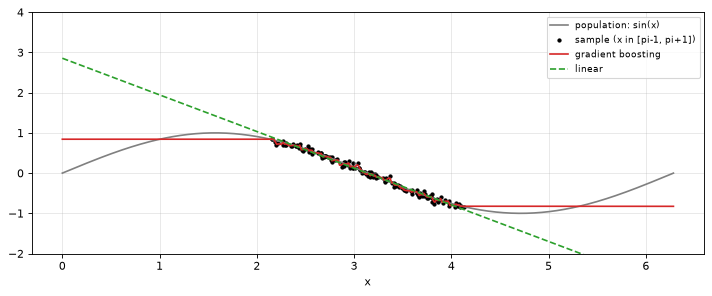

In [15]:
rng = np.random.default_rng(1)
x_seen = rng.uniform(np.pi - 1, np.pi + 1, 150).reshape(-1, 1)
y_seen = np.sin(x_seen.ravel()) + rng.normal(0, 0.05, 150)
x_all = np.linspace(0, 2 * np.pi, 400).reshape(-1, 1)
inside = (x_all.ravel() >= np.pi - 1) & (x_all.ravel() <= np.pi + 1)

gb_s = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, max_depth=2, random_state=0).fit(x_seen, y_seen)
lin_s = LinearRegression().fit(x_seen, y_seen)
print(f"linear fit on the sample: y = {lin_s.intercept_:.3f} {lin_s.coef_[0]:+.3f} x   (the line pi - x is 3.142 - 1.000 x)")
for name, model in [("gradient boosting", gb_s), ("linear", lin_s)]:
    pred = model.predict(x_all)
    print(f"{name:<18} RMSE vs sin(x): inside the sampled stretch {rmse(np.sin(x_all.ravel()[inside]), pred[inside]):.3f}, "
          f"outside {rmse(np.sin(x_all.ravel()[~inside]), pred[~inside]):.3f}")

plt.figure(figsize=(9, 3.8))
plt.plot(x_all, np.sin(x_all), color="gray", label="population: sin(x)")
plt.scatter(x_seen, y_seen, s=8, color="black", label="sample (x in [pi-1, pi+1])")
plt.plot(x_all, gb_s.predict(x_all), color="tab:red", label="gradient boosting")
plt.plot(x_all, lin_s.predict(x_all), color="tab:green", ls="--", label="linear")
plt.ylim(-2, 4); plt.xlabel("x"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

> **How to read this**
> * Inside the sampled stretch both models are accurate (RMSE 0.036 boosting, 0.026 linear).
> * Outside, **neither** recovers sin(x): boosting goes flat at the edge values (±0.84) and the line keeps going
>   straight. Boosting's error outside (0.32) happens to be smaller than the line's (1.45) only because sin(x) stays
>   between −1 and 1 — the flat line is "less wrong" by luck, it still misses both humps. The data simply contains no
>   information about the rest of the curve.
> * The lesson is about the **sample, not the algorithm**: a flexible model learns the sample's shape, and where the
>   sample stops, its knowledge stops. Gradient boosting's specific way of failing is the flat line.

## Lab 14 · Interactions: stumps cannot learn XOR (depth 2 can)

**Goal:** README section 8.3. A sum of stumps is an **additive** model: f(x1) + g(x2), no term that depends on both
at once. XOR ("class 1 when exactly one of x1, x2 is positive") and sin(x1 + x2) are pure interactions. We compare
`max_depth` 1, 2 and 3.

In [16]:
rng = np.random.default_rng(2)
X_xor = rng.uniform(-1, 1, (2000, 2))
y_xor = ((X_xor[:, 0] > 0) ^ (X_xor[:, 1] > 0)).astype(int)
y_sin = np.sin(3 * (X_xor[:, 0] + X_xor[:, 1])) + rng.normal(0, 0.1, 2000)
Xx_tr, Xx_te, yx_tr, yx_te, ys_tr, ys_te = train_test_split(X_xor, y_xor, y_sin, test_size=0.3, random_state=0)

for depth in [1, 2, 3]:
    c = GradientBoostingClassifier(n_estimators=200, max_depth=depth, random_state=0).fit(Xx_tr, yx_tr)
    r = GradientBoostingRegressor(n_estimators=200, max_depth=depth, random_state=0).fit(Xx_tr, ys_tr)
    print(f"max_depth = {depth}: XOR test accuracy {accuracy_score(yx_te, c.predict(Xx_te)):.3f}   "
          f"sin(3(x1+x2)) test R2 {r2_score(ys_te, r.predict(Xx_te)):.3f}")

for depth in [1, 3]:
    m_ = GradientBoostingRegressor(n_estimators=1000, max_depth=depth, random_state=0).fit(X_tr, y_tr)
    print(f"good-fit data, max_depth = {depth}: best validation MSE {min(mean_squared_error(y_va, p) for p in m_.staged_predict(X_va)):.3f}")

max_depth = 1: XOR test accuracy 0.577   sin(3(x1+x2)) test R2 -0.006


max_depth = 2: XOR test accuracy 0.997   sin(3(x1+x2)) test R2 0.753


max_depth = 3: XOR test accuracy 0.995   sin(3(x1+x2)) test R2 0.907


good-fit data, max_depth = 1: best validation MSE 2.824


good-fit data, max_depth = 3: best validation MSE 1.837


> **How to read this**
> * With stumps (`max_depth=1`) XOR stays near coin-flip accuracy (**0.577**) and sin(3(x1+x2)) is not learned at all
>   (R² **−0.006**); with depth 2 XOR is solved (**0.997**) and the sine mostly learned (R² 0.753; 0.907 at depth 3). One split on x1 followed by one on x2 *inside the same tree* is exactly an interaction.
> * Rule of thumb: `max_depth = d` lets each tree model interactions of up to d features. The old note "y = x1 XOR x2
>   fails" is only true for stumps; scikit-learn's default is `max_depth=3`.
> * The good-fit data has an x1·x2 interaction too, so stumps are clearly worse there (best validation MSE 2.824 vs
>   1.837 with depth 3).

## Lab 15 · Outliers: squared loss chases them

**Goal:** README section 8.4. Corrupt 5 % of the training targets with huge errors and compare the three regression
losses, judged on **clean** test data.

squared_error   RMSE against the clean curve sin(x): 1.317
absolute_error  RMSE against the clean curve sin(x): 0.115


huber           RMSE against the clean curve sin(x): 0.540
huber, alpha=0.5 RMSE against the clean curve sin(x): 0.476   (delta = median absolute error instead of the 90th percentile)


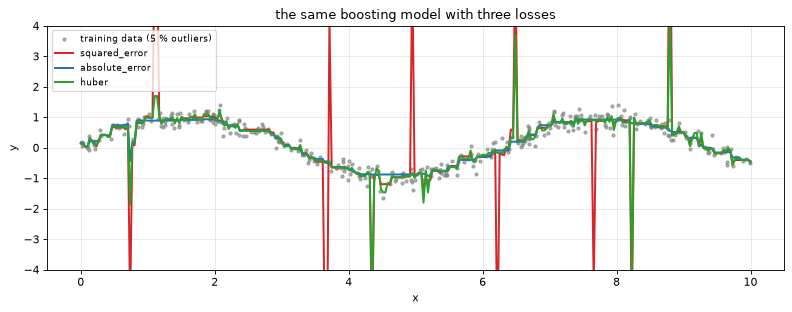

In [17]:
rng = np.random.default_rng(3)
x_o = np.sort(rng.uniform(0, 10, 400)).reshape(-1, 1)
y_clean = np.sin(x_o.ravel()) + rng.normal(0, 0.2, 400)
y_dirty = y_clean.copy()
bad = rng.choice(400, 20, replace=False)                               # 5 % of the rows
y_dirty[bad] += rng.choice([-1, 1], 20) * rng.uniform(5, 10, 20)
x_test = np.linspace(0, 10, 300).reshape(-1, 1)

fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(x_o, y_dirty, s=8, color="gray", alpha=0.6, label="training data (5 % outliers)")
for loss, color in zip(["squared_error", "absolute_error", "huber"], ["tab:red", "tab:blue", "tab:green"]):
    model = GradientBoostingRegressor(loss=loss, n_estimators=300, learning_rate=0.1, max_depth=3,
                                      random_state=0).fit(x_o, y_dirty)
    pred = model.predict(x_test)
    print(f"{loss:<15} RMSE against the clean curve sin(x): {rmse(np.sin(x_test.ravel()), pred):.3f}")
    ax.plot(x_test, pred, color=color, lw=1.8, label=loss)
huber_half = GradientBoostingRegressor(loss="huber", alpha=0.5, n_estimators=300, random_state=0).fit(x_o, y_dirty)
print(f"huber, alpha=0.5 RMSE against the clean curve sin(x): {rmse(np.sin(x_test.ravel()), huber_half.predict(x_test)):.3f}"
      "   (delta = median absolute error instead of the 90th percentile)")
ax.set(ylim=(-4, 4), xlabel="x", ylabel="y", title="the same boosting model with three losses")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

> **How to read this**
> * Squared loss pulls the curve towards every outlier (its pseudo-residual grows with the error, Lab 3): RMSE
>   **1.317** against the clean curve, with a spike at almost every outlier. Absolute loss ignores how far off a point
>   is and stays on sin(x) (**0.115**).
> * Huber with the default `alpha=0.9` sets δ at the 90th percentile of the current errors, so with 5 % outliers it
>   still lets part of their pull through (**0.540**, smaller spikes). Lowering `alpha` to 0.5 helps only a little
>   here (**0.476**). For gross outliers like these, absolute loss is the robust choice; Huber suits moderate ones.
> * scikit-learn starts absolute/Huber models at the **median** (not the mean) and sets each leaf to the **median** of
>   its residuals (absolute) or a median-plus-capped-correction (Huber) — robust statistics all the way down.
> * Plot cut at |y| = 4, so some outliers lie off-screen.

## Lab 16 · Noisy labels and too many rounds

**Goal:** README section 8.5. With 30 % of labels flipped at random, big steps and deep trees, every extra round
memorises more noise. We watch training and validation log-loss.

validation log-loss: best 0.491 at 9 trees, after 500 trees 0.909; training log-loss after 500 trees 0.002
500 rounds                   test log-loss 1.078, test accuracy 0.755
early stopping (19 rounds)   test log-loss 0.529, test accuracy 0.761


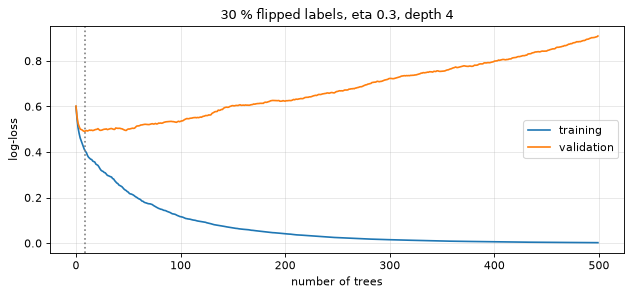

In [18]:
Xn, yn = make_classification(n_samples=3000, n_features=10, n_informative=5, flip_y=0.3, random_state=0)
Xn_tv, Xn_te, yn_tv, yn_te = train_test_split(Xn, yn, test_size=0.25, random_state=0)
Xn_tr, Xn_va, yn_tr, yn_va = train_test_split(Xn_tv, yn_tv, test_size=0.25, random_state=0)
noisy = GradientBoostingClassifier(n_estimators=500, learning_rate=0.3, max_depth=4, random_state=0).fit(Xn_tr, yn_tr)
tr_ll = [log_loss(yn_tr, p) for p in noisy.staged_predict_proba(Xn_tr)]
va_ll = [log_loss(yn_va, p) for p in noisy.staged_predict_proba(Xn_va)]
best = int(np.argmin(va_ll)) + 1
print(f"validation log-loss: best {min(va_ll):.3f} at {best} trees, after 500 trees {va_ll[-1]:.3f}; "
      f"training log-loss after 500 trees {tr_ll[-1]:.3f}")
stopped = GradientBoostingClassifier(n_estimators=500, learning_rate=0.3, max_depth=4, n_iter_no_change=10,
                                     random_state=0).fit(Xn_tv, yn_tv)
for name, model in [("500 rounds", noisy), (f"early stopping ({stopped.n_estimators_} rounds)", stopped)]:
    print(f"{name:<28} test log-loss {log_loss(yn_te, model.predict_proba(Xn_te)):.3f}, "
          f"test accuracy {accuracy_score(yn_te, model.predict(Xn_te)):.3f}")

plt.figure(figsize=(8, 3.8))
plt.plot(tr_ll, label="training"); plt.plot(va_ll, label="validation")
plt.axvline(best, color="gray", ls=":")
plt.xlabel("number of trees"); plt.ylabel("log-loss"); plt.title("30 % flipped labels, eta 0.3, depth 4")
plt.legend(); plt.tight_layout(); plt.show()

> **How to read this**
> * The validation log-loss is best after only **9 trees** (0.491) and then **climbs steadily** to 0.909, while training
>   log-loss heads to 0 (0.002): the extra rounds learn the flipped labels.
> * Early stopping (on a slice of the training data) stops after **19 rounds**: test log-loss **0.529** instead of
>   **1.078**. Accuracy hardly moves (0.761 vs 0.755) — the damage is in the **probabilities**, which become
>   over-confident. Smaller η, shallower trees and `subsample < 1` also help.
> * Note what is *not* on this list: class imbalance, data drift and "limited data" are not gradient-boosting-specific
>   failures (they hurt every model; a small, regularised GBM is a standard small-data baseline).

## Lab 17 · A purely linear target, and the residual-correlation diagnostic

**Goal:** README section 8.7 and the old notebook's diagnostic. When y is a straight-line function of the features,
trees must build each slope from many little steps. Correlating the **validation residuals** with each feature shows
what the model failed to capture.

In [19]:
Xl, yl = make_regression(n_samples=1000, n_features=10, n_informative=4, noise=0.2, random_state=42)
Xl_tr, Xl_va, yl_tr, yl_va = train_test_split(Xl, yl, test_size=0.2, random_state=42)
models_l = {"gradient boosting": GradientBoostingRegressor(random_state=0),
            "random forest": RandomForestRegressor(random_state=0, n_jobs=-1),
            "linear regression": LinearRegression()}
print(f"{'model':<18}{'val RMSE':>9}   correlation(residual, feature j) for j = 0..9")
for name, model in models_l.items():
    resid = yl_va - model.fit(Xl_tr, yl_tr).predict(Xl_va)
    corr = np.array([np.corrcoef(resid, Xl_va[:, j])[0, 1] for j in range(10)])
    print(f"{name:<18}{rmse(yl_va, model.predict(Xl_va)):>9.2f}   {np.array2string(corr, precision=2)}")
print("the informative features (largest true coefficients):", np.sort(np.argsort(np.abs(np.linalg.lstsq(Xl_tr, yl_tr, rcond=None)[0]))[-4:]))

model              val RMSE   correlation(residual, feature j) for j = 0..9


gradient boosting      6.11   [ 0.04  0.29 -0.03  0.    0.   -0.05  0.03  0.4   0.39  0.31]
random forest         10.15   [ 0.02  0.44 -0.01  0.02  0.03 -0.09  0.04  0.31  0.5   0.5 ]
linear regression      0.20   [ 0.02 -0.1   0.13 -0.07 -0.02  0.    0.07 -0.11 -0.06 -0.12]
the informative features (largest true coefficients): [1 7 8 9]


> **How to read this**
> * The linear model's error is the noise level (**0.20**) and its residuals show no clear correlation with any feature.
> * Both tree ensembles leave errors 30–50 times larger (boosting **6.11**, forest **10.15**), and their residuals still
>   **correlate with the four informative features 1, 7, 8, 9** (0.29–0.40 for boosting, 0.31–0.50 for the forest):
>   part of each straight-line effect was never captured, because a staircase can only approximate a slope. Boosting
>   does better than the forest but remains far from the line.
> * Diagnostic to keep: if validation residuals correlate with a feature, the model has left signal in that feature —
>   consider a linear term, a transformed feature, or a model with a linear part.

## Lab 18 · Cost: sequential training, large data, tuning sensitivity

**Goal:** README section 8.6. (a) Boosting rounds must run one after another, so fit time grows linearly with the
number of trees and cannot be spread across cores the way a random forest can. (b) For large n, the histogram
version is much faster. (c) Results depend on several interacting knobs.

 100 boosting rounds:  0.15 s


 200 boosting rounds:  0.31 s


 400 boosting rounds:  0.62 s


 800 boosting rounds:  1.24 s


random forest, 400 trees, n_jobs= 1:  1.00 s
random forest, 400 trees, n_jobs=-1:  0.20 s


n = 50,000: GradientBoostingRegressor      fit 18.26 s, test R2 0.952


n = 50,000: HistGradientBoostingRegressor  fit  1.17 s, test R2 0.954


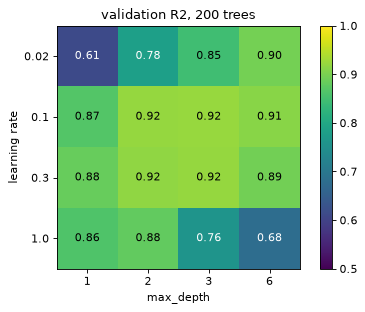

In [20]:
for n_trees in [100, 200, 400, 800]:
    t0 = time.perf_counter()
    GradientBoostingRegressor(n_estimators=n_trees, random_state=0).fit(X_tr, y_tr)
    t_gb = time.perf_counter() - t0
    print(f"{n_trees:>4} boosting rounds: {t_gb:5.2f} s")
for jobs in [1, -1]:
    t0 = time.perf_counter()
    RandomForestRegressor(n_estimators=400, n_jobs=jobs, random_state=0).fit(X_tr, y_tr)
    print(f"random forest, 400 trees, n_jobs={jobs:>2}: {time.perf_counter() - t0:5.2f} s")

X_big, y_big = make_friedman1(n_samples=60000, n_features=10, noise=1.0, random_state=1)
Xg_tr, Xg_te, yg_tr, yg_te = train_test_split(X_big, y_big, test_size=10000, random_state=0)
for name, model in [("GradientBoostingRegressor", GradientBoostingRegressor(n_estimators=200, random_state=0)),
                    ("HistGradientBoostingRegressor", HistGradientBoostingRegressor(max_iter=200, early_stopping=False,
                                                                                    random_state=0))]:
    t0 = time.perf_counter()
    model.fit(Xg_tr, yg_tr)
    print(f"n = 50,000: {name:<30} fit {time.perf_counter() - t0:5.2f} s, test R2 {r2_score(yg_te, model.predict(Xg_te)):.3f}")

etas, depths_ = [0.02, 0.1, 0.3, 1.0], [1, 2, 3, 6]
grid_r2 = np.array([[r2_score(y_va, GradientBoostingRegressor(n_estimators=200, learning_rate=e, max_depth=d,
                                                              random_state=0).fit(X_tr, y_tr).predict(X_va))
                     for d in depths_] for e in etas])
plt.figure(figsize=(5.5, 4))
plt.imshow(grid_r2, cmap="viridis", vmin=0.5, vmax=1.0)
for i in range(len(etas)):
    for j in range(len(depths_)):
        plt.text(j, i, f"{grid_r2[i, j]:.2f}", ha="center", va="center", color="white" if grid_r2[i, j] < 0.8 else "black")
plt.xticks(range(len(depths_)), depths_); plt.yticks(range(len(etas)), etas)
plt.xlabel("max_depth"); plt.ylabel("learning rate"); plt.title("validation R2, 200 trees"); plt.colorbar()
plt.grid(False); plt.tight_layout(); plt.show()

> **How to read this**
> * Fit time doubles when the number of rounds doubles (the four printed times grow ×2 each step): round m needs the
>   residuals of round m−1, so rounds cannot run in parallel. A random forest's trees are independent, so `n_jobs=-1`
>   spreads them over all cores and is several times faster than `n_jobs=1`.
> * On 50,000 rows the classic `GradientBoostingRegressor` takes close to 20 s; `HistGradientBoostingRegressor`
>   (features binned into at most 255 bins, like LightGBM/XGBoost's `hist` method; see [`../../06-xgboost/`](../../06-xgboost/README.md)) is several
>   times faster for the same accuracy (R² 0.954 vs 0.952). Use it for n ≳ 10,000. (Exact timings depend on the machine
>   and on what else is running.)
> * The heat map: the same 200 trees give validation R² anywhere from **0.61 to 0.92** depending on η and depth. The
>   knobs interact (small η needs more trees; deep trees need smaller η), so tune them together on validation data.

---
# Summary — what each lab showed

| Lab | Claim from the README | Verdict |
|---|---|---|
| 1 | Hand example: F₀ = 5, stumps at 3.5 / 4.5 / 5.5, MSE 10.667 → 3.917 → 1.573 → 0.814 | ✔ same numbers as scikit-learn |
| 2 | Screenshot numbers: F₀ = ln(5/3), tree-1 leaves 1.6 / −2.67 / 0.18 | ✔ (tree-2 leaves recomputed: 0.58 / −2.99 / 1.05) |
| 3 | Pseudo-residual = −∂L/∂F (squared, absolute, Huber, log-loss) | ✔ numeric = formula |
| 4 | Each tree fixes what is left; training error keeps falling | ✔ |
| 5 | Binary: F₀ is the log-odds, Newton leaves Σr/Σp(1−p) | ✔ hand loop = scikit-learn |
| 6 | K classes: K trees per round, sum-zero start, softmax shift-invariance, (K−1)/K | ✔ |
| 7 | Beats linear, one tree and a random forest on non-linear tabular data | ✔ |
| 8 | Validation curve has a minimum; training curve does not | ✔ |
| 9 | Smaller learning rate → more trees, slightly better | ✔ tested |
| 10 | Early stopping works; `validation_fraction` alone does nothing | ✔ |
| 11 | `subsample`: new subset every round, without replacement | ✔ |
| 12 | ✘ Future of a trend: flat forecast; trend model wins | failure shown |
| 13 | ✘ Only the sampled stretch is learned | failure shown |
| 14 | ✘ Stumps cannot learn interactions (depth 2 can) | failure shown |
| 15 | ✘ Squared loss chases outliers (absolute / Huber fix it) | failure shown |
| 16 | ✘ Noisy labels + too many rounds over-fit (early stopping fixes it) | failure shown |
| 17 | ✘ Linear target: staircase approximation; residuals stay correlated | failure shown |
| 18 | ✘ Sequential cost, slow for large n, sensitive to tuning | failure shown |